# Task 2 · Problem 4 · Part 1 — LLN, confidence intervals, and CLT

Simulate Gamma data using shape k = 2 and scale θ = 5. No input CSV is needed.

Source: [assignment_2.pdf](../input/assignment_2.pdf). Розв’язання та висновки наведено нижче українською мовою.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

TASK_DIR = Path.cwd()
if (TASK_DIR / "labs" / "task2").is_dir():
    TASK_DIR = TASK_DIR / "labs" / "task2"
elif TASK_DIR.name == "notebooks":
    TASK_DIR = TASK_DIR.parent
INPUT_DIR = TASK_DIR / "input"
PDF_DIR = TASK_DIR / "pdf"
FIGURES_DIR = PDF_DIR / "figures"
SEED = 42
ALPHA = 0.05
rng = np.random.default_rng(SEED)
sns.set_theme(style="whitegrid")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = PDF_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})


In [2]:
SHAPE = 2
SCALE = 5
TRUE_MEAN = 10
TRUE_VARIANCE = 50
SAMPLE_SIZES = 5 ** np.arange(1, 9)  # 5¹ through 5⁸, not 51 through 58
REPLICATIONS = 1000
SMALL_N = 4
LARGE_N = 100


## 1(a) — Sample moments and the weak law of large numbers

Generate Gamma(2, 5) samples for n = 5¹, …, 5⁸. Compute each sample mean and sample variance. Plot means versus n using a logarithmic x-axis; discuss the weak law of large numbers. State whether samples are independent or nested, and use an explicit variance convention (`ddof=1` for unbiased sample variance).

,n,mean,variance
0,5,11.488704,9.876565
1,25,8.890425,21.964613
2,125,10.097676,63.121252
3,625,9.831200,45.690043
4,3125,10.120737,49.760696
5,15625,10.057645,51.695993
6,78125,9.996694,50.433119
7,390625,9.996343,49.777707


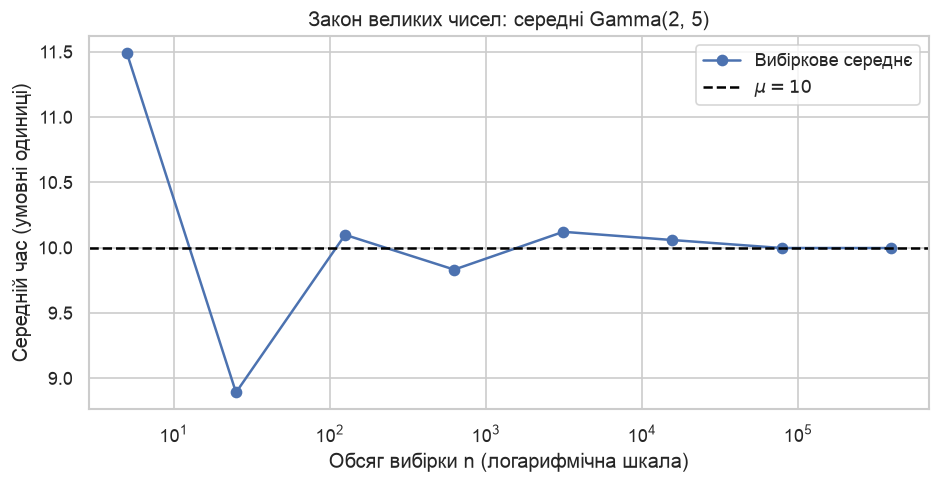

In [3]:
samples = [rng.gamma(shape=SHAPE, scale=SCALE, size=int(n)) for n in SAMPLE_SIZES]
moments = pd.DataFrame({
    "n": SAMPLE_SIZES,
    "mean": [x.mean() for x in samples],
    "variance": [x.var(ddof=1) for x in samples],
})
display(moments.round(6))
moments.to_csv(RESULTS_DIR / "part1_moments.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(moments["n"], moments["mean"], "o-", label="Вибіркове середнє")
ax.axhline(TRUE_MEAN, color="black", linestyle="--", label=r"$\mu=10$")
ax.set(xscale="log", xlabel="Обсяг вибірки n (логарифмічна шкала)",
       ylabel="Середній час (умовні одиниці)", title="Закон великих чисел: середні Gamma(2, 5)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part1_lln.pdf")
plt.show()

***Answer***

Використано незалежні, а не вкладені вибірки: для кожного $n=5^1,\ldots,5^8$ генерується нова вибірка. Параметр $\theta=5$ є масштабом. Тому
$$\mu=k\theta=10,\qquad \sigma^2=k\theta^2=50.$$
Обчислено
$$\bar X=\frac1n\sum_{i=1}^nX_i,\qquad s^2=\frac1{n-1}\sum_{i=1}^n(X_i-\bar X)^2.$$
При $n=5$ отримано $\bar x=11.4887$, а при $n=390625$ маємо $\bar x=9.9963$ та $s^2=49.7777$. Великі вибірки дають середні, близькі до 10. За слабким законом великих чисел для кожного $\varepsilon>0$ маємо $P(|\bar X_n-10|>\varepsilon)\to0$. Графік узгоджується з цим твердженням, але не доводить його. Збіжність не означає монотонного зменшення похибки в кожній реалізації. Для оцінки середнього часу між сесіями більша вибірка зазвичай дає точніший результат.

## 1(b) — 95% confidence intervals

Calculate intervals manually, first with the known theoretical standard deviation, then with the sample standard deviation. Add both to the plot. State and justify the critical values used and discuss approximation quality for small and large n; Gamma data are not normally distributed.

,n,mean,known_lower,known_upper,estimated_lower,estimated_upper
0,5,11.488704,5.290754,17.686655,7.586526,15.390882
1,25,8.890425,6.118618,11.662233,6.955874,10.824976
2,125,10.097676,8.858086,11.337266,8.691175,11.504177
3,625,9.831200,9.276839,10.385562,9.300240,10.362161
4,3125,10.120737,9.872819,10.368655,9.873317,10.368157
5,15625,10.057645,9.946773,10.168518,9.944900,10.170391
6,78125,9.996694,9.947111,10.046278,9.946896,10.046493
7,390625,9.996343,9.974168,10.018517,9.974218,10.018468


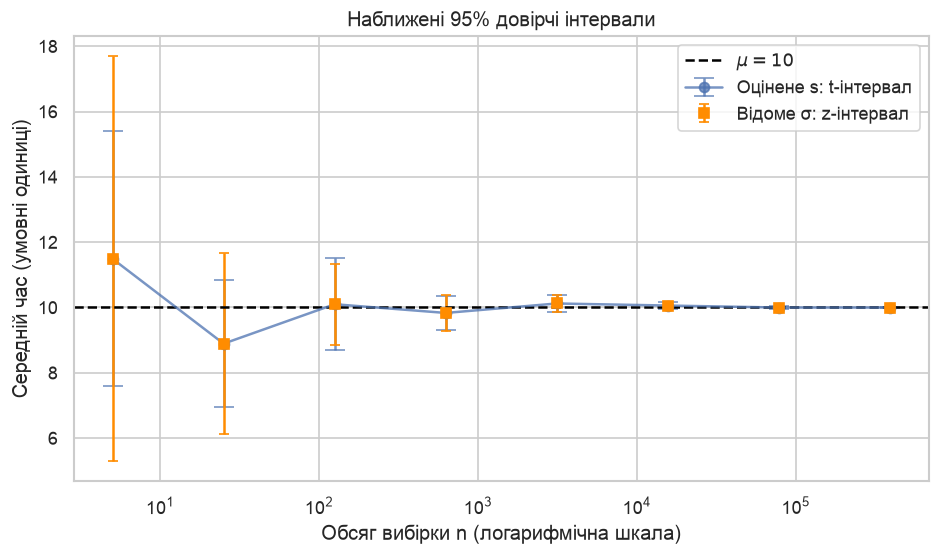

In [4]:
z_critical = stats.norm.ppf(1 - ALPHA / 2)
t_critical = stats.t.ppf(1 - ALPHA / 2, df=SAMPLE_SIZES - 1)
known_margin = z_critical * np.sqrt(TRUE_VARIANCE / SAMPLE_SIZES)
estimated_margin = t_critical * np.sqrt(moments["variance"] / SAMPLE_SIZES)
intervals = moments[["n", "mean"]].copy()
intervals["known_lower"] = moments["mean"] - known_margin
intervals["known_upper"] = moments["mean"] + known_margin
intervals["estimated_lower"] = moments["mean"] - estimated_margin
intervals["estimated_upper"] = moments["mean"] + estimated_margin
display(intervals.round(6))
intervals.to_csv(RESULTS_DIR / "part1_intervals.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.errorbar(SAMPLE_SIZES, moments["mean"], yerr=estimated_margin,
            fmt="o-", capsize=6, alpha=0.75, label="Оцінене s: t-інтервал")
ax.errorbar(SAMPLE_SIZES, moments["mean"], yerr=known_margin,
            fmt="s", capsize=3, color="darkorange", label="Відоме σ: z-інтервал")
ax.axhline(TRUE_MEAN, color="black", linestyle="--", label=r"$\mu=10$")
ax.set(xscale="log", xlabel="Обсяг вибірки n (логарифмічна шкала)",
       ylabel="Середній час (умовні одиниці)", title="Наближені 95% довірчі інтервали")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part1_intervals.pdf")
plt.show()

***Answer***

Інтервали побудовано за формулами
$$I_\sigma=\left[\bar x-z_{0.975}\frac{\sqrt{50}}{\sqrt n},\ \bar x+z_{0.975}\frac{\sqrt{50}}{\sqrt n}\right],\qquad z_{0.975}\approx1.9600,$$
$$I_s=\left[\bar x-t_{0.975,n-1}\frac{s}{\sqrt n},\ \bar x+t_{0.975,n-1}\frac{s}{\sqrt n}\right].$$
Другий інтервал використовує оцінене стандартне відхилення та квантиль Стьюдента. Обидва інтервали тут **наближені**: Gamma-дані не є нормальними, а точний t-інтервал вимагає нормальності генеральної сукупності. При малих $n$ фактичне покриття може відрізнятися від 95%.

Для $n=5$ отримано $I_\sigma=[5.2908;\ 17.6867]$ та $I_s=[7.5865;\ 15.3909]$. У цій вибірці $s^2=9.8766$ значно менша за 50, тому інтервал з оціненим $s$ вужчий, попри більший t-квантиль. Він не зобов’язаний завжди бути ширшим. При великих $n$ маємо $s\to\sigma$, t-квантиль наближається до z-квантиля, а ЦГТ покращує нормальне наближення. Ширина інтервалів зменшується приблизно як $1/\sqrt n$.

У цій реалізації всі інтервали містять 10. Вісім інтервалів не є оцінкою довгострокового 95% покриття. Рівень 95% характеризує частку інтервалів, які накривали б фіксоване $\mu$ при багаторазовому повторенні процедури за відповідних умов.

## 1(c) — Repeated small samples

Generate b = 1000 samples of size n = 4 from Gamma(2, 5). Save each sample mean and variance. Plot histograms of the 1000 means and 1000 variances.

,mean,variance
mean,10.134969,50.980956
var,13.080444,3053.456482


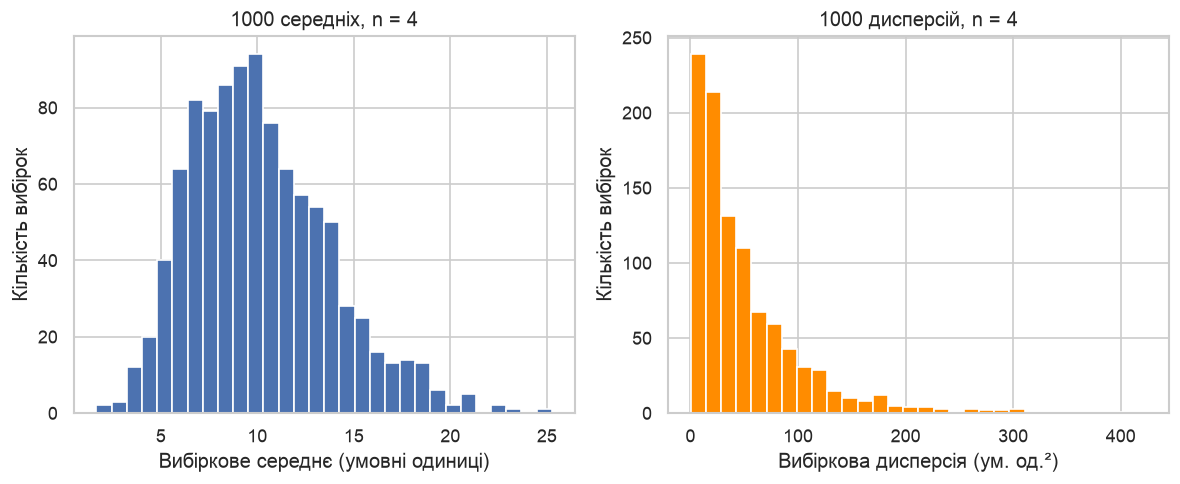

In [5]:
small_samples = rng.gamma(shape=SHAPE, scale=SCALE, size=(REPLICATIONS, SMALL_N))
small_means = small_samples.mean(axis=1)
small_variances = small_samples.var(axis=1, ddof=1)
repeated_moments = pd.DataFrame({"mean": small_means, "variance": small_variances})
repeated_moments.to_csv(RESULTS_DIR / "part1_repeated_moments.csv", index=False)
display(repeated_moments.agg(["mean", "var"]).round(6))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].hist(small_means, bins=30, edgecolor="white")
axes[0].set(xlabel="Вибіркове середнє (умовні одиниці)", ylabel="Кількість вибірок",
            title="1000 середніх, n = 4")
axes[1].hist(small_variances, bins=30, edgecolor="white", color="darkorange")
axes[1].set(xlabel="Вибіркова дисперсія (ум. од.²)", ylabel="Кількість вибірок",
            title="1000 дисперсій, n = 4")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part1_histograms.pdf")
plt.show()

***Answer***

Згенеровано 1000 незалежних вибірок обсягу 4. Для кожної збережено $\bar x$ та незміщену дисперсію $s^2$ з дільником $n-1=3$. Середнє 1000 оцінок $\bar x$ дорівнює 10.1350, а середнє 1000 оцінок $s^2$ становить 50.9810. Вони близькі до 10 і 50 відповідно. Обидві гістограми мають праву асиметрію; дисперсії особливо нестійкі для такої малої вибірки. Окремі великі значення збільшують правий хвіст гістограми дисперсій.

## 1(d) — Analytical moments

Derive E[(X₁ + X₂ + X₃ + X₄)/4] and Var[(X₁ + X₂ + X₃ + X₄)/4], stating independence assumptions. The PDF’s general remark about unknown non-normal sum distributions does not preclude a known exact distribution for this specific Gamma case.

In [6]:
mean_of_mean = SHAPE * SCALE
variance_of_mean = SHAPE * SCALE**2 / SMALL_N
mean_comparison = pd.DataFrame({
    "quantity": ["E(mean)", "Var(mean)", "E(sample variance)"],
    "theoretical": [mean_of_mean, variance_of_mean, TRUE_VARIANCE],
    "simulation": [small_means.mean(), small_means.var(ddof=1), small_variances.mean()],
})
display(mean_comparison.round(6))
mean_comparison.to_csv(RESULTS_DIR / "part1_comparison.csv", index=False)

,quantity,theoretical,simulation
0,E(mean),10.0,10.134969
1,Var(mean),12.5,13.080444
2,E(sample variance),50.0,50.980956


***Answer***

Нехай $X_1,\ldots,X_4$ незалежні й однаково розподілені як $\Gamma(2,5)$. За лінійністю сподівання
$$E(\bar X)=\frac14\sum_{i=1}^4E(X_i)=\frac{4\cdot10}{4}=10.$$
Незалежність дає нульові коваріації, тому
$$\operatorname{Var}(\bar X)=\frac1{16}\sum_{i=1}^4\operatorname{Var}(X_i)=\frac{4\cdot50}{16}=12.5.$$
Звідси стандартне відхилення середнього дорівнює $\sqrt{12.5}\approx3.5355$. Емпірична дисперсія 1000 середніх становить 13.0804, що близько до 12.5. Незалежність потрібна саме для використаної формули дисперсії.

## 1(e) — Normal approximation

Overlay a normal density using the analytically derived mean and variance on a density-normalized histogram of sample means. Explain the fit at n = 4 and what changes at n = 100 using the CLT; optionally simulate n = 100 to illustrate.

***Answer***

Перед побудовою графіка очікую, що при $n=4$ нормальна щільність лише приблизно описуватиме середні: асиметрія ще помітна. При $n=100$ за ЦГТ наближення має бути кращим, а дисперсія середнього зменшиться з $50/4$ до $50/100$. Додаткове моделювання для $n=100$ не виконується, оскільки воно необов’язкове.

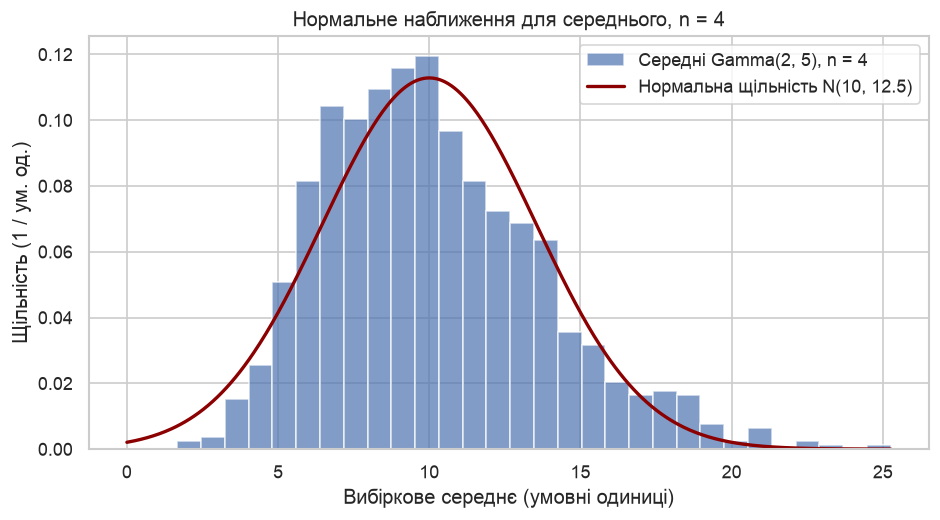

In [7]:
x_grid = np.linspace(min(0, small_means.min()), small_means.max(), 500)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(small_means, bins=30, density=True, edgecolor="white", alpha=0.7,
        label="Середні Gamma(2, 5), n = 4")
ax.plot(x_grid, stats.norm.pdf(x_grid, loc=mean_of_mean, scale=np.sqrt(variance_of_mean)),
        color="darkred", linewidth=2, label="Нормальна щільність N(10, 12.5)")
ax.set(xlabel="Вибіркове середнє (умовні одиниці)", ylabel="Щільність (1 / ум. од.)",
       title="Нормальне наближення для середнього, n = 4")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part1_normal_approximation.pdf")
plt.show()

***Answer***

На гістограму щільності накладено нормальну щільність $N(10,12.5)$, де другий параметр позначає дисперсію. Її центр і масштаб близькі до емпіричних, однак гістограма при $n=4$ залишається асиметричною; симетрична нормальна крива не відтворює правий хвіст і навіть допускає від’ємні середні. Це узгоджується з прогнозом перед побудовою графіка.

За ЦГТ для незалежних однаково розподілених величин зі скінченними сподіванням і дисперсією
$$\frac{\sqrt n(\bar X_n-10)}{\sqrt{50}}\ \xrightarrow{d}\ N(0,1).$$
При $n=100$ очікуємо краще наближення $\bar X_{100}\approx N(10,0.5)$: середнє залишається 10, а дисперсія дорівнює $50/100=0.5$. Саме збільшення обсягу кожної вибірки покращує нормальне наближення. Збільшення кількості повторень при незмінному $n=4$ лише точніше показало б той самий ненормальний розподіл середнього.